# 0. Setup

In [1]:
import json
import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

SEED = 12
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


In [2]:
# Model 
D_MODEL = 64
N_HEADS = 2
N_LAYERS = 2
TIME_SCALE = 100.0

# Dataset
DATASET_SIZE = 100_000
N_POINTS = 24
PROMPT_LEN = 4

# Training
N_EPOCHS = 60_001
BATCH_SIZE = 64

In [3]:
def plot_sample(prompt, pts):
    fig, (text_ax, img_ax) = plt.subplots(1, 2, figsize=(4, 2))
    text_ax.axis("off")
    text_ax.text(1.0, 0.5, prompt, fontsize=10, ha="right", va="center",
                 transform=text_ax.transAxes, color="black")
    if len(pts):
        img_ax.scatter(pts[:, 0], pts[:, 1], s=3, c="black", alpha=0.6)
    img_ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
    img_ax.set_xticks([-3, 0, 3])
    img_ax.set_yticks([-3, 0, 3])
    img_ax.tick_params(labelsize=10, colors="grey")
    for spine in img_ax.spines.values():
        spine.set_color("grey")
    plt.tight_layout()
    plt.show()

# 1. Data

In [4]:
HELD_OUT_PROMPTS = {
    "circle on triangle",
    "circle above triangle",
    "triangle under circle",
    "triangle below circle",
}

VOCAB = [
    "PAD",
    "circle", "square", "triangle", "dot",
    "on", "above", "under", "below", "left", "right", "of"
]
WORD_TO_IDX = {w: i for i, w in enumerate(VOCAB)}
VOCAB_SIZE, PAD = len(VOCAB), 0

def tokenize(sentence, max_len=PROMPT_LEN):
    ids = [WORD_TO_IDX.get(w, PAD) for w in sentence.lower().split()][:max_len]
    return ids + [PAD] * (max_len - len(ids))

def detokenize(ids):
    return " ".join(VOCAB[i] for i in ids if i != PAD)

SHAPES = ["circle", "square", "triangle", "dot"]
SCALE = 0.80
PLACEMENT_GAP = 0.85
SAME_SHAPE_PROB = 0.20

RELATIONS = [
    dict(dir=(0,  1), syns=["on", "above"]),
    dict(dir=(0, -1), syns=["under", "below"]),
    dict(dir=(-1, 0), syns=["left", "left of"]),
    dict(dir=(1,  0), syns=["right", "right of"]),
]

def shape_outline(shape, n):
    if shape == "dot":
        return np.zeros((n, 2), dtype=np.float32)

    if shape == "circle":
        theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
        return np.stack([np.cos(theta), np.sin(theta)], axis=1).astype(np.float32)

    if shape == "square":
        v = [(-1, -1), (-1, 1), (1, 1), (1, -1)]
    else:  # triangle
        v = [(0, 1), (-1, -0.7), (1, -0.7)]

    n_v = len(v)
    pts_per_side, extras = divmod(n, n_v)

    res = []
    for i in range(n_v):
        count = pts_per_side + (1 if i < extras else 0)
        start, end = np.array(v[i]), np.array(v[(i + 1) % n_v])
        side_pts = np.linspace(start, end, num=count, endpoint=False)
        res.append(side_pts)

    return np.vstack(res).astype(np.float32)

def place_shape(shape, n, center):
    raw_pts = shape_outline(shape, n)
    return raw_pts * SCALE + center

def make_scene():
    if np.random.random() < 0.5:
        shape = np.random.choice(SHAPES)
        pts = place_shape(shape, N_POINTS, center=np.zeros(2))
        prompt = shape
    else:
        if np.random.random() < SAME_SHAPE_PROB:
            s1 = s2 = np.random.choice(SHAPES)
        else:
            s1, s2 = np.random.choice(SHAPES, 2, replace=False)
        rel = np.random.choice(RELATIONS)

        dist = SCALE + SCALE + PLACEMENT_GAP
        offset = np.array(rel["dir"]) * (dist / 2)

        n1 = N_POINTS // 2
        n2 = N_POINTS - n1
        pts = np.vstack([
            place_shape(s1, n1, center=offset),
            place_shape(s2, n2, center=-offset),
        ])
        pts = pts[np.random.permutation(len(pts))]  # Break fixed slot assignments between the two shapes
        prompt = " ".join([s1, np.random.choice(rel["syns"]), s2])

    return pts.astype(np.float32), np.array(tokenize(prompt), dtype=np.int64)

def build_dataset(n=DATASET_SIZE):
    held_out = {tuple(tokenize(p)) for p in HELD_OUT_PROMPTS}

    def sample():
        while True:
            pts, toks = make_scene()
            if tuple(toks) not in held_out:
                return pts, toks

    pts, toks = zip(*(sample() for _ in range(n)))
    pts, toks = torch.from_numpy(np.stack(pts)), torch.from_numpy(np.stack(toks))

    if device == "cuda":
        pts, toks = pts.pin_memory(), toks.pin_memory()
    print(f"Dataset → {n} scenes, {N_POINTS} points each")
    return pts, toks

dataset = build_dataset()

Dataset → 100000 scenes, 24 points each


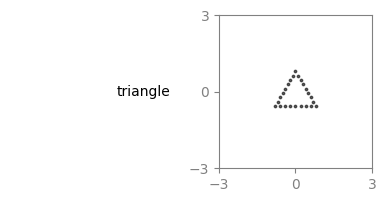

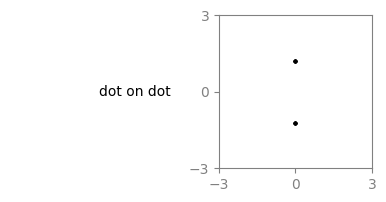

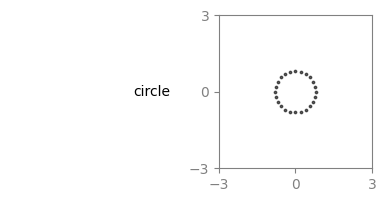

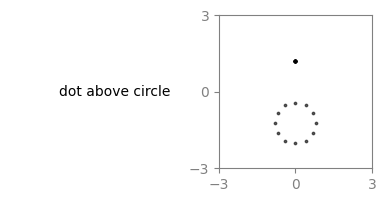

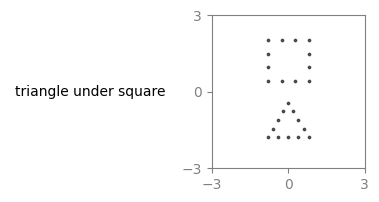

In [5]:
for i in range(5):
    pts_all, tok_all = dataset
    plot_sample(detokenize(tok_all[i].tolist()), pts_all[i].numpy())

# 2. Model

In [6]:
class SinusoidalEmbedding(nn.Module):
    def __init__(self, d_model, base=500.0):
        super().__init__()
        self.d_model, self.base = d_model, base

    def forward(self, x):
        half = self.d_model // 2
        freq = torch.exp(-math.log(self.base) *
                         torch.arange(half, device=x.device).float() / half)
        args = torch.outer(x.float(), freq)
        return torch.cat([args.sin(), args.cos()], dim=-1)


class TextEncoder(nn.Module):
    def __init__(self, vocab_size, d_model, pos_base=10.0):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        self.pos_emb = SinusoidalEmbedding(d_model, base=pos_base)

    def forward(self, tokens):
        positions = torch.arange(tokens.shape[1], device=tokens.device)
        tok_emb = self.token_emb(tokens)
        pos_emb = self.pos_emb(positions).unsqueeze(0).expand(tokens.shape[0], -1, -1)
        return tok_emb + pos_emb, tok_emb


class DiTLayer(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=0.0, batch_first=True)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            nn.GELU(),
            nn.Linear(d_model * 4, d_model),
        )

    def forward(self, x, key_padding_mask):
        xn = self.norm1(x)
        attn_out, attn_weights = self.attn(
            xn, xn, xn, key_padding_mask=key_padding_mask,
            need_weights=True, average_attn_weights=False,
        )
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x, attn_weights


class DiTFlowModel(nn.Module):
    def __init__(self, d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS,
                 time_base=500.0, time_scale=TIME_SCALE, pos_base=10.0):
        super().__init__()
        self.time_scale = time_scale
        self.text_enc = TextEncoder(VOCAB_SIZE, d_model, pos_base)
        self.time_emb = SinusoidalEmbedding(d_model, base=time_base)
        self.point_proj = nn.Linear(2, d_model)
        self.layers = nn.ModuleList(DiTLayer(d_model, n_heads) for _ in range(n_layers))
        self.out_proj = nn.Linear(d_model, 2)  # Outputs 2D velocity vector per point

    def forward(self, x, t, tokens):
        B, n_points = x.shape[0], x.shape[1]

        # Scale continuous t in [0, 1] to the frequency domain
        time_tok = self.time_emb(t * self.time_scale).unsqueeze(1)
        text_seq, text_tok_emb = self.text_enc(tokens)
        point_seq = self.point_proj(x)
        seq = torch.cat([time_tok, text_seq, point_seq], dim=1)
        seq_pre = seq

        pad_mask = torch.zeros(B, 1 + PROMPT_LEN + n_points, dtype=torch.bool, device=x.device)
        pad_mask[:, 1:1 + PROMPT_LEN] = (tokens == PAD)

        attn_per_layer = []
        for layer in self.layers:
            seq, attn = layer(seq, pad_mask)
            attn_per_layer.append(attn)

        return {
            "v_pred":      self.out_proj(seq[:, 1 + PROMPT_LEN:]),
            "attention":   torch.stack(attn_per_layer, dim=0),
            "emb":         seq_pre,
            "post_dit":    seq,
            "txt_tok_emb": text_tok_emb,
        }

model = DiTFlowModel().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS, eta_min=1e-4)

print(f"Model initialized → Params: {sum(p.numel() for p in model.parameters()):,}")

Model initialized → Params: 101,058


# 3. Training

In [7]:
def get_batch(dataset, batch_size):
    x0, tokens = dataset
    idx = torch.randint(0, len(x0), (batch_size,))
    return x0[idx].to(device, non_blocking=True), tokens[idx].to(device, non_blocking=True)

running_loss, running_n = 0.0, 0
for epoch in range(N_EPOCHS):
    x0, tokens = get_batch(dataset, BATCH_SIZE)

    # 1. Sample continuous time t in [0, 1]
    t = torch.rand(x0.shape[0], device=device)
    t_expanded = t[:, None, None]

    # 2. Sample pure Gaussian noise x1 ~ N(0, I)
    x1 = torch.randn_like(x0)

    # 3. Flow Matching Linear Interpolation: xt = (1 - t)*x0 + t*x1
    xt = (1.0 - t_expanded) * x0 + t_expanded * x1

    # 4. Target constant velocity along the straight path: v = x1 - x0
    v_target = x1 - x0

    # 5. Predict velocity with DiT (t in [0, 1] is scaled internally)
    v_pred = model(xt, t, tokens)["v_pred"]
    loss = nn.functional.mse_loss(v_pred, v_target)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()

    running_loss += loss.item()
    running_n += 1
    if epoch % 3000 == 0 and epoch > 0:
        print(f"Epoch {epoch:>5}  avg3000 {running_loss/running_n:.5f}  lr {scheduler.get_last_lr()[0]:.2e}")
        running_loss, running_n = 0.0, 0

Epoch  3000  avg3000 0.91440  lr 9.94e-04
Epoch  6000  avg3000 0.84617  lr 9.78e-04
Epoch  9000  avg3000 0.82303  lr 9.51e-04
Epoch 12000  avg3000 0.81084  lr 9.14e-04
Epoch 15000  avg3000 0.80352  lr 8.68e-04
Epoch 18000  avg3000 0.79709  lr 8.14e-04
Epoch 21000  avg3000 0.79371  lr 7.54e-04
Epoch 24000  avg3000 0.79204  lr 6.89e-04
Epoch 27000  avg3000 0.78687  lr 6.20e-04
Epoch 30000  avg3000 0.78590  lr 5.50e-04
Epoch 33000  avg3000 0.78203  lr 4.80e-04
Epoch 36000  avg3000 0.77967  lr 4.11e-04
Epoch 39000  avg3000 0.77861  lr 3.46e-04
Epoch 42000  avg3000 0.77589  lr 2.85e-04
Epoch 45000  avg3000 0.77556  lr 2.32e-04
Epoch 48000  avg3000 0.77471  lr 1.86e-04
Epoch 51000  avg3000 0.77011  lr 1.49e-04
Epoch 54000  avg3000 0.77074  lr 1.22e-04
Epoch 57000  avg3000 0.76542  lr 1.06e-04
Epoch 60000  avg3000 0.76882  lr 1.00e-04


# 4. Inference

In Training Set


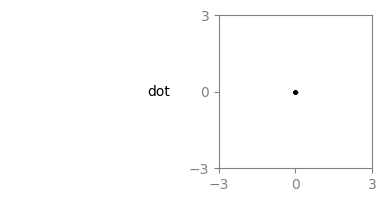

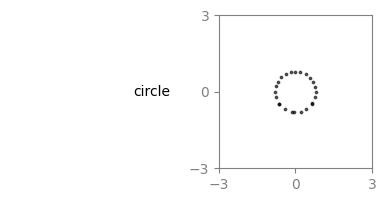

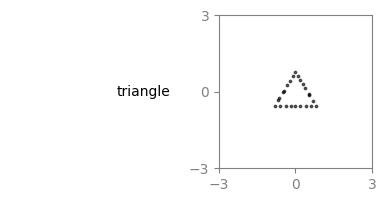

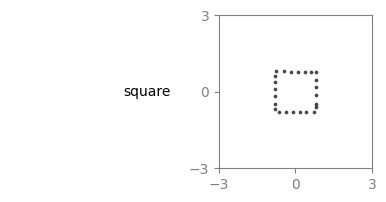

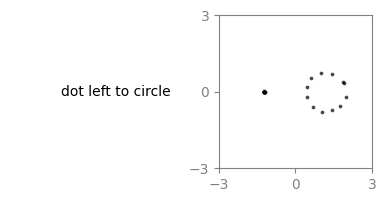

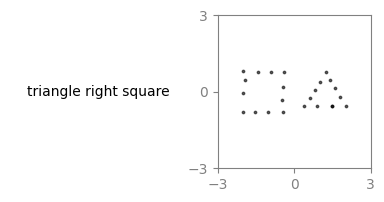

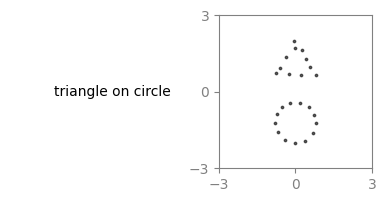

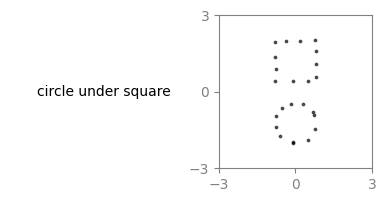

Not in Training Set


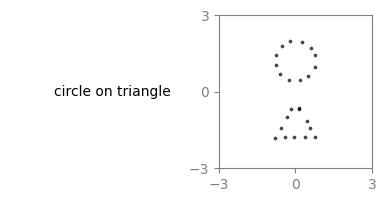

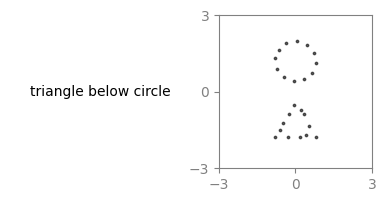

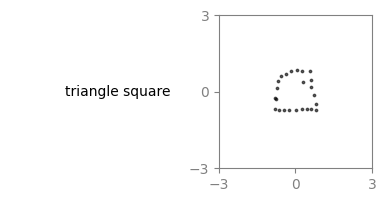

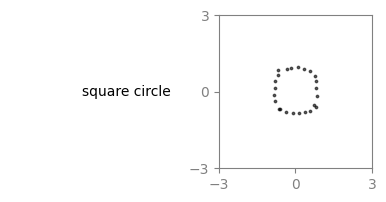

In [8]:
model.eval()

def time_shift(t, s=0.3):
    return s * t / (1 + (s - 1) * t)

@torch.no_grad()
def generate(prompt, num_steps=100, s=0.3):
    tokens = torch.tensor(tokenize(prompt), dtype=torch.long, device=device).unsqueeze(0)
    x = torch.randn(1, N_POINTS, 2, device=device)

    uniform = torch.linspace(1.0, 0.0, num_steps + 1, device=device)
    shifted = time_shift(uniform, s)

    for i in range(num_steps):
        t_tensor = shifted[i].reshape(1)
        dt = shifted[i] - shifted[i + 1]
        v_pred = model(x, t_tensor, tokens)["v_pred"]
        x = x - dt * v_pred

    return x.squeeze(0).cpu().numpy()

def show_generation(prompt, num_steps=20):
    pts = generate(prompt, num_steps=num_steps)
    plot_sample(prompt, pts)

print("In Training Set")
show_generation("dot")
show_generation("circle")
show_generation("triangle")
show_generation("square")
show_generation("dot left to circle")
show_generation("triangle right square")
show_generation("triangle on circle")
show_generation("circle under square")
print("Not in Training Set")
show_generation("circle on triangle")
show_generation("triangle below circle")
show_generation("triangle square")
show_generation("square circle")

# 5. Export

In [9]:
torch.onnx.export(
    model,
    (
        torch.zeros(1, N_POINTS, 2, dtype=torch.float, device=device),
        torch.tensor([1.0], dtype=torch.float, device=device),  # Dummy t in [0, 1]
        torch.full((1, PROMPT_LEN), PAD, dtype=torch.long, device=device),
    ),
    "dit_flow_matching.onnx",
    input_names=["x", "t", "tokens"],
    output_names=["v_pred", "attention", "emb", "post_dit", "txt_tok_emb"],
    dynamic_axes={
        "x":           {0: "batch"},
        "t":           {0: "batch"},
        "tokens":      {0: "batch"},
        "v_pred":      {0: "batch"},
        "attention":   {1: "batch"},
        "emb":         {0: "batch"},
        "post_dit":    {0: "batch"},
        "txt_tok_emb": {0: "batch"},
    },
    opset_version=17,
    do_constant_folding=True,
    dynamo=False,
)
print("Exported → dit_flow_matching.onnx")

def _round(data, precision=4):
    if isinstance(data, dict):
        return {k: _round(v, precision) for k, v in data.items()}
    if isinstance(data, list):
        return [_round(v, precision) for v in data]
    return round(float(data), precision)

def export_weights(name, **tensors):
    data = {k: t.detach().cpu().numpy().tolist() for k, t in tensors.items()}
    with open(f"{name}.json", "w") as f:
        json.dump(_round(data), f, indent=2)
    print(f"Exported → {name}.json")

export_weights("dit_text_encoder_embedding", weight=model.text_enc.token_emb.weight)
export_weights(
    "dit_text_encoder_pos_embedding",
    weight=model.text_enc.pos_emb(torch.arange(PROMPT_LEN, device=device)),
)
export_weights("dit_pos_proj", weight=model.point_proj.weight, bias=model.point_proj.bias)
export_weights("dit_out_proj", weight=model.out_proj.weight, bias=model.out_proj.bias)

Exported → dit_flow_matching.onnx
Exported → dit_text_encoder_embedding.json
Exported → dit_text_encoder_pos_embedding.json
Exported → dit_pos_proj.json
Exported → dit_out_proj.json
